<center><h1>Zhan_Jenna_Midterm1</h1></center>
<br>
<br>

Name: Jenna Zhan
<br>
Github Username: jenna-zhan
<br>
USC ID: 2477604908

# 8. Programming Question: Predicting Housing Prices with Linear Regression

## (a) Data Exploration and Pre-processing

### i. Import the student-mat.csv dataset as a pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [2]:
student_mat = pd.read_csv("../data/student-mat.csv",sep=";")
print(student_mat.shape)
student_mat.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### ii. Select the following features: age, studytime, schoolsup, goout, Dalc,Walc, health, absences, G3 (target/dependent variable). Encode the binary variable (schoolsup) values as 0s (no) and 1s (yes). Combine Dalc and Walc into one variable alc by taking averge, then remove Dalc and Walc.Display the first five rows of the pre-processed dataset.

In [3]:
selected_features = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]
selected_data = student_mat[selected_features].copy()

selected_data["schoolsup"] = selected_data["schoolsup"].map({"no": 0, "yes": 1})

selected_data["alc"] = (selected_data["Dalc"] + selected_data["Walc"]) / 2
selected_data = selected_data.drop(columns=["Dalc", "Walc"])

print(selected_data.shape)
print(selected_data.dtypes)
selected_data.head()

(395, 8)
age            int64
studytime      int64
schoolsup      int64
goout          int64
health         int64
absences       int64
G3             int64
alc          float64
dtype: object


,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


### iii. Find the number of outliers for each independent variable using the IQR method.

In [4]:
outliers_number = []

ind_data = selected_data.drop(columns=["G3"])

for col in ind_data.columns:
    
    Q1 = ind_data[col].quantile(0.25)
    Q3 = ind_data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    number = ((ind_data[col] < lower_bound) | (ind_data[col] > upper_bound)).sum()
    
    outliers_number.append({"variable": col, "number of outliers": number})

outliers_df = pd.DataFrame(outliers_number)
print(outliers_df)

    variable  number of outliers
0        age                   1
1  studytime                  27
2  schoolsup                  51
3      goout                   0
4     health                   0
5   absences                  15
6        alc                   9


### iv. Standardize and run PCA on the dataset. Create a scatterplot of PC1 vs PC2, coloring the dots by their final grade G3. Inspect the component loadings and determine which features contribute the most to PC1 and PC2. Keep and use standardized data for remaining problems.

In [5]:
X = selected_data[["age", "studytime", "schoolsup", "goout", "health", "absences", "alc"]]
y = selected_data["G3"]

ind_mean = ind_data.mean()
ind_std = ind_data.std()
ind_scaled = (ind_data - ind_mean) / ind_std

print(ind_scaled.mean())
print(ind_scaled.std())

age          1.223213e-15
studytime   -2.788206e-16
schoolsup    1.798842e-17
goout       -1.641444e-16
health       7.195369e-17
absences    -4.497106e-17
alc         -6.295948e-17
dtype: float64
age          1.0
studytime    1.0
schoolsup    1.0
goout        1.0
health       1.0
absences     1.0
alc          1.0
dtype: float64


In [6]:
pca_data = PCA(n_components=2)
X_pca = pca_data.fit_transform(ind_scaled)

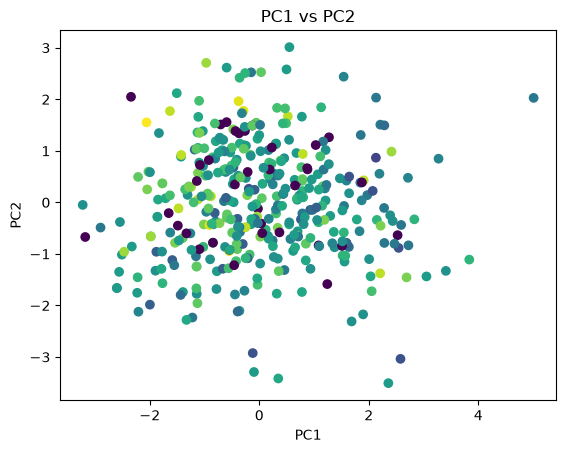

In [7]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c = y,
)
plt.title("PC1 vs PC2")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

In [8]:
loadings_df = pd.DataFrame(
    pca_data.components_.T, 
    index = ["age", "studytime", "schoolsup", "goout", "health", "absences", "alc"], 
    columns = ["PC1 loading", "PC2 loading"]
)

print(loadings_df)

           PC1 loading  PC2 loading
age           0.381940     0.589260
studytime    -0.329734     0.385671
schoolsup    -0.248184    -0.464202
goout         0.493755    -0.139613
health        0.080545    -0.400925
absences      0.280106     0.182798
alc           0.595871    -0.273677


Based on the absolute component loadings,alcohol contributes the most to PC1, while age contributes the most to PC2.

## (b) Linear Regression

### i. Split data into training set and testing set with an 80:20 ratio. Use random seed 552 for reproducibility.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    ind_scaled, y,
    test_size = 0.2,
    random_state = 552
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(316, 7) (79, 7)
(316,) (79,)


### ii. Build three models using the training set: A. Linear Regression Model, B. Linear Regression Model with Ridge Regularization, and C. Linear Regression Model with Lasso Regularization. Set α=0.1.

In [10]:
model_a = LinearRegression()
model_a.fit(X_train, y_train)

model_b = Ridge(alpha=0.1)
model_b.fit(X_train, y_train)

model_c = Lasso(alpha=0.1, random_state=552)
model_c.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",552
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### iii. Test all three models on the test set. Find out the best performing model with repsect to each of the metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

In [11]:
y_pred_a = model_a.predict(X_test)
y_pred_b = model_b.predict(X_test)
y_pred_c = model_c.predict(X_test)

In [12]:
y_true = np.array(y_test)
n = len(y_true)
y_mean = np.mean(y_true)
sst = np.sum((y_true - y_mean) ** 2)

In [13]:
#a
residuals_a = y_true - y_pred_a
mae_a = np.sum(np.abs(residuals_a)) / n
rmse_a = np.sqrt(np.sum(residuals_a ** 2) / n)
ssr_a = np.sum(residuals_a ** 2)
r2_a = 1 - (ssr_a / sst)

In [14]:
#b
residuals_b = y_true - y_pred_b
mae_b = np.sum(np.abs(residuals_b)) / n
rmse_b = np.sqrt(np.sum(residuals_b ** 2) / n)
ssr_b = np.sum(residuals_b ** 2)
r2_b = 1 - (ssr_b / sst)

In [15]:
#c
residuals_c = y_true - y_pred_c
mae_c = np.sum(np.abs(residuals_c)) / n
rmse_c = np.sqrt(np.sum(residuals_c ** 2) / n)
ssr_c = np.sum(residuals_c ** 2)
r2_c = 1 - (ssr_c / sst)

In [16]:
results_df = pd.DataFrame({
    "model": ["Linear Regression Model",
              "Linear Regression Model with Ridge Regularization (alpha=0.1)",
              "Linear Regression Model with Lasso Regularization (alpha=0.1)"],
    "MAE": [mae_a, mae_b, mae_c],
    "RMSE": [rmse_a, rmse_b, rmse_c],
    "R2": [r2_a, r2_b, r2_c]
}).set_index("model")
results_df

,MAE,RMSE,R2
model,,,
Linear Regression Model,3.418009,4.755812,0.028177
Linear Regression Model with Ridge Regularization (alpha=0.1),3.418062,4.755859,0.028157
Linear Regression Model with Lasso Regularization (alpha=0.1),3.447115,4.793890,0.012552


Lower MAE and RMSE values and higher R^2 value indicate better performance. Among the three models, Linear Regression and Ridge Regression have relatively lower MAE and RMSE values. Linear Regression also has a slightly higher R^2 value. Therefore, the Linear Regression model performs the best overall.

### iv. How do you interpret R² values from the three models?

The R^2 values of the Linear and Ridge regression models are approximately 0.028, meaning that these two models explain only about 2.8% of the variation in G3 in the test set. The R^2 value of the Lasso regression model is approximately 0.013, meaning that it explains only about 1.3% of the variation in G3 in the test set. All three R^2 values are very low, indicating that these independent variables have weak explanatory power for G3.

### v. Print coefficients of independent variables from the three models in one table.

In [17]:
coef_df = pd.DataFrame({
    "variable": ["age", "studytime", "schoolsup", "goout", "health", "absences", "alc"],
    "Linear Regression Model": model_a.coef_,
    "Linear Regression Model with Ridge Regularization": model_b.coef_,
    "Linear Regression Model with Lasso Regularization": model_c.coef_
}).set_index("variable")

coef_df

,Linear Regression Model,Linear Regression Model with Ridge Regularization,Linear Regression Model with Lasso Regularization
variable,,,
age,-0.782068,-0.781728,-0.630990
studytime,0.445376,0.445219,0.349423
schoolsup,-0.683338,-0.683055,-0.547983
goout,-0.583258,-0.583050,-0.486111
health,-0.243633,-0.243535,-0.141622
absences,0.193044,0.192939,0.071976
alc,0.037120,0.036955,-0.000000


In [18]:
print("linear regression intercept:", model_a.intercept_)
print("ridge intercept:", model_b.intercept_)
print("lasso intercept:", model_c.intercept_)

linear regression intercept: 10.629377845616373
ridge intercept: 10.629364648925481
lasso intercept: 10.625099769480949


### vi. What’s the relationship between each independent variable and the dependent variable?

Holding all other variables constant, age, school support, going out, and health have negative relationships with G3, while study time and absences have positive relationships with G3. Alcohol consumption has a very small positive coefficient in the Linear and Ridge models, indicating almost no linear relationship with G3. Lasso reduces the alcohol coefficient to zero, suggesting that alcohol contributes little additional predictive information under this model.

### vii. How do the regularization methods differ? What can you conclude about the dataset and features given the results?

Ridge regression shrinks all coefficients toward zero but usually does not set them exactly to zero. Lasso regression can shrink some coefficients to exactly zero and therefore perform feature selection.

The results of Ridge regression are very close to those of ordinary linear regression, indicating that Ridge does not significantly improve model performance. Lasso reduces the coefficient of alc to zero and shrinks almost all the other coefficients toward zero compared with ordinary linear regression. However, according to the MAE, RMSE, and R^2 results, Lasso performs worse than the other two models.

### viii. If the regularization strength (α) is increased, what would happen to performance metrics?

A larger alpha would make the Ridge coefficients move closer to zero compared with those of ordinary linear regression, while Lasso would shrink more coefficients to exactly zero. At the current value of alpha=0.1, neither Ridge nor Lasso performs better than ordinary linear regression, and Lasso performs slightly worse. Therefore, increasing alpha may cause stronger underfitting, resulting in higher MAE and RMSE values and a lower R^2 value.

### ix. What are some feature engineering methods you would suggest to improve model performance?

Since only a subset of the available variables was selected as independent variables when building the models, we could include more relevant independent variables to improve model performance. We could also add quadratic terms and interaction terms to capture possible nonlinear relationships and interactions among the variables.